# Chapitre 10 - Cours 2 : ordre, identifiants et horloges logiques

Attribuer un identifiant à un enregistrement semble sans rapport avec la cohérence. Et
pourtant : si les identifiants servent à **ordonner** les événements (afficher une
conversation, choisir le gagnant d'une réservation, construire un instantané), leur
ordre doit respecter la **causalité**, voire le **temps réel**. Ce notebook part de la
relation « s'est produit avant », compare les générateurs d'identifiants distribués,
implémente les horloges de Lamport et vectorielles, et montre pourquoi des horodatages,
même bien ordonnés, ne suffisent pas à imposer une contrainte d'unicité. Il couvre la section *ID Generators and Logical Clocks* : *Logical Clocks*, *Lamport timestamps*, *Hybrid logical clocks*, *Lamport/hybrid logical clocks versus vector clocks*, *Linearizable ID Generators* (*Implementing a linearizable ID generator*, *Enforcing constraints using logical clocks*).

**Plan.**

1. Causalité : un ordre partiel.
2. Un compteur sur un seul nœud : ordonné, linéarisable, mais fragile.
3. Les générateurs distribués perdent l'ordre.
4. Les horloges de Lamport : un ordre total compatible avec la causalité.
5. Les horloges vectorielles : reconnaître la concurrence.
6. Des horodatages ne suffisent pas à imposer une contrainte.

7. Les horloges logiques hybrides.
8. Les générateurs d'identifiants linéarisables.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, DIV, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Causalité : un ordre partiel (section *Logical Clocks*)

L'**ordre** revient sans cesse dans ce livre : le leader impose l'ordre des écritures
dans le journal de réplication, la sérialisabilité fait comme si les transactions
s'exécutaient dans un certain ordre, les horodatages des horloges servent à décider
quelle écriture est la plus récente. Une raison profonde : l'ordre aide à préserver la
**causalité**. Une réponse vient après la question à laquelle elle répond ; une ligne ne
peut être modifiée qu'après avoir été créée ; un instantané cohérent contient les effets
de tout ce qui a précédé causalement ce qu'il contient.

**La relation « s'est produit avant »** (happens-before, chapitre 6). Un
événement $a$ précède causalement $b$ ($a \to b$) si : $a$ et $b$ ont lieu sur le même
nœud et $a$ vient d'abord ; ou $a$ est l'envoi d'un message et $b$ sa réception ; ou il
existe $c$ avec $a \to c$ et $c \to b$. Si ni $a \to b$ ni $b \to a$, les deux
événements sont **concurrents** ($a \parallel b$) : aucun n'a pu influencer l'autre.

C'est un **ordre partiel** : deux événements concurrents ne sont pas comparables. Un ordre
**total**, lui, compare n'importe quelle paire (deux entiers, par exemple). La
linéarisabilité impose un ordre total (une seule copie, des opérations atomiques une à
une) ; la causalité, seulement un ordre partiel. Rejouons un échange entre trois nœuds et
calculons la relation entre chaque paire d'événements.

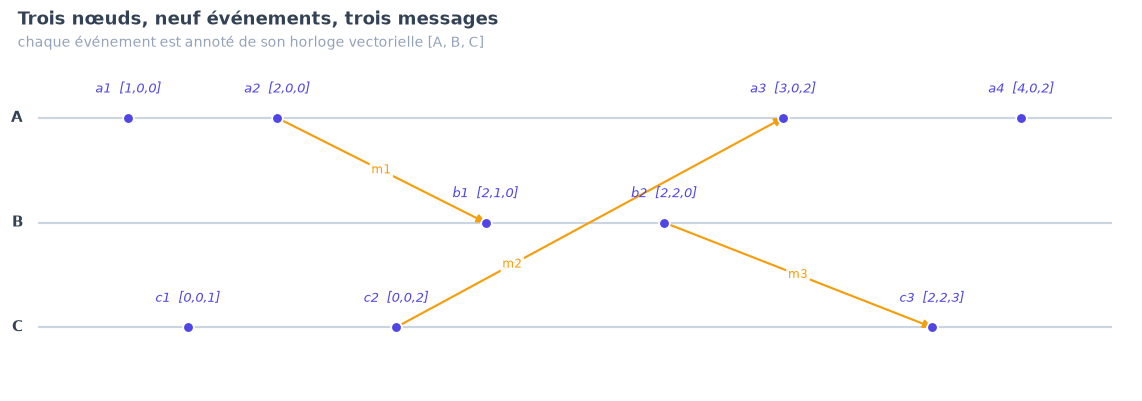

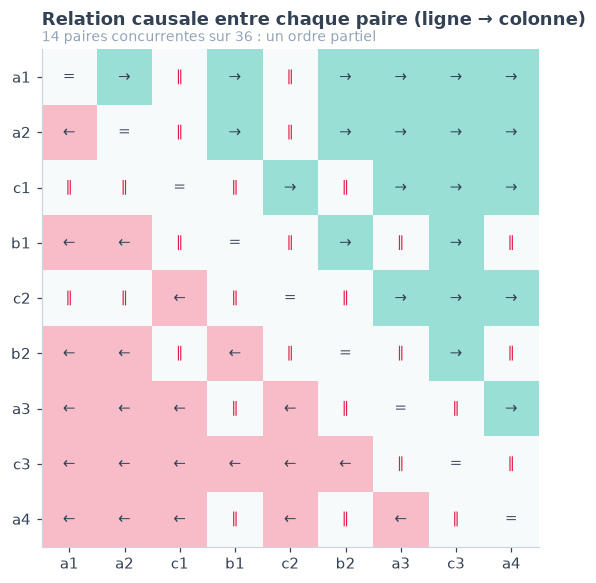

In [2]:
def rejoue(actions, nodes):
    """actions : ('local', nœud, nom) | ('send', nœud, nom, msg) | ('recv', nœud, nom, msg).
    Renvoie la liste des événements avec horloges de Lamport et vectorielles."""
    lam = {n: cs.LamportClock(n) for n in nodes}
    vec = {n: cs.VectorClock(n, nodes) for n in nodes}
    sent, out = {}, []
    for a in actions:
        kind, node, name = a[:3]
        if kind == "recv":
            lam[node].observe(sent[a[3]][0]); vec[node].observe(sent[a[3]][1])
        ev = dict(nom=name, nœud=node, type=kind, lamport=lam[node].tick(), vc=vec[node].tick())
        if kind == "send":
            sent[a[3]] = (ev["lamport"], ev["vc"])
        out.append(ev)
    return out

nodes = ["A", "B", "C"]
actions = [("local", "A", "a1"), ("send", "A", "a2", "m1"), ("local", "C", "c1"), ("recv", "B", "b1", "m1"),
           ("send", "C", "c2", "m2"), ("send", "B", "b2", "m3"), ("recv", "A", "a3", "m2"),
           ("recv", "C", "c3", "m3"), ("local", "A", "a4")]
evs = rejoue(actions, nodes)
pos = {"a1": 0.6, "a2": 1.6, "c1": 1.0, "b1": 3.0, "c2": 2.4, "b2": 4.2, "a3": 5.0, "c3": 6.0, "a4": 6.6}
msgs = {"m1": ("a2", "b1"), "m2": ("c2", "a3"), "m3": ("b2", "c3")}
st = SpaceTime(nodes, t_max=7.2, width=10.5, title="Trois nœuds, neuf événements, trois messages",
               subtitle="chaque événement est annoté de son horloge vectorielle [A, B, C]", show_axis=False)
for m, (s_, r_) in msgs.items():
    st.msg(evs[[e["nom"] for e in evs].index(s_)]["nœud"], pos[s_], evs[[e["nom"] for e in evs].index(r_)]["nœud"], pos[r_],
           m, color=AMBER, label_pos=0.3 if m == "m2" else 0.5)
for e in evs:
    st.event(e["nœud"], pos[e["nom"]], "", color=INDIGO)
    st.note(pos[e["nom"]], e["nœud"], f"{e['nom']}  [{','.join(str(v) for v in e['vc'].values())}]", dy=0.28,
            color=INDIGO, fontsize=8.5)
st.show()

names = [e["nom"] for e in evs]
code = {"<": 1, ">": -1, "=": 0, "||": 0}
M = np.array([[code[cs.vc_compare(a["vc"], b["vc"])] for b in evs] for a in evs])
conc = np.array([[cs.vc_compare(a["vc"], b["vc"]) == "||" for b in evs] for a in evs])
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.imshow(M, cmap=DIV, vmin=-1.6, vmax=1.6)
for i in range(len(evs)):
    for j in range(len(evs)):
        sym = {1: "→", -1: "←", 0: "∥" if conc[i, j] else "="}[M[i, j]]
        ax.text(j, i, sym, ha="center", va="center", fontsize=10, color=SLATE if sym != "∥" else ROSE)
ax.set_xticks(range(len(evs)), names); ax.set_yticks(range(len(evs)), names)
ax.grid(False)
ax.set_title("Relation causale entre chaque paire (ligne → colonne)")
subtitle(ax, f"{conc.sum() // 2} paires concurrentes sur {len(evs) * (len(evs) - 1) // 2} : un ordre partiel")
plt.tight_layout(); plt.show()

Lecture de la matrice : `a1 → b1` (a1 précède l'envoi de m1, reçu en b1) ; `c1 ∥ a2`
(aucun chemin de messages entre eux) ; `a1 → c3` par la chaîne a1, a2, m1, b1, b2, m3,
c3. Un événement est comparé à un autre **seulement** s'il existe un chemin dans le
diagramme espace-temps. On dit qu'un système est **cohérent avec la causalité** s'il
respecte cet ordre partiel : par exemple, l'isolation par instantané (chapitre
8) exige qu'un instantané qui contient un événement contienne aussi
tout ce qui l'a causé.

> **À retenir.** La causalité ($a \to b$ : un chemin de messages ou d'événements locaux
> mène de $a$ à $b$) est un ordre **partiel** ; les événements sans chemin entre eux sont
> concurrents. Un ordre total (linéarisabilité, numéros de séquence) compare tout.

## 2. Un compteur sur un seul nœud : ordonné, linéarisable, mais fragile (section *ID Generators and Logical Clocks*)

Une base sur un seul nœud attribue souvent des clés primaires par **auto-incrément** :
64 bits suffisent (32 si l'on est sûr de ne jamais dépasser 4 milliards
d'enregistrements, pari risqué). En prime, l'ordre des identifiants est l'ordre de
création : dans une messagerie, trier par identifiant affiche les messages dans un ordre
qui a du sens (une réponse a un identifiant plus grand que la question).

Ce générateur est **linéarisable** : chaque demande est un `fetch-and-add` atomique
(incrémenter un compteur et renvoyer l'ancienne valeur). Si la demande A se termine avant
que la demande B ne commence, B reçoit un identifiant plus grand, même si A et B n'ont
jamais communiqué. Deux demandes concurrentes reçoivent des identifiants distincts, dans
un ordre quelconque.

En mémoire, c'est une instruction atomique du processeur. Le rendre persistant demande
un peu plus d'effort (un redémarrage ne doit pas remettre le compteur à zéro, sinon les
identifiants se répètent). Mais ses vrais défauts sont ailleurs : c'est un **point de
défaillance unique**, un **goulot d'étranglement** potentiel, et il est **loin** de
certains clients.

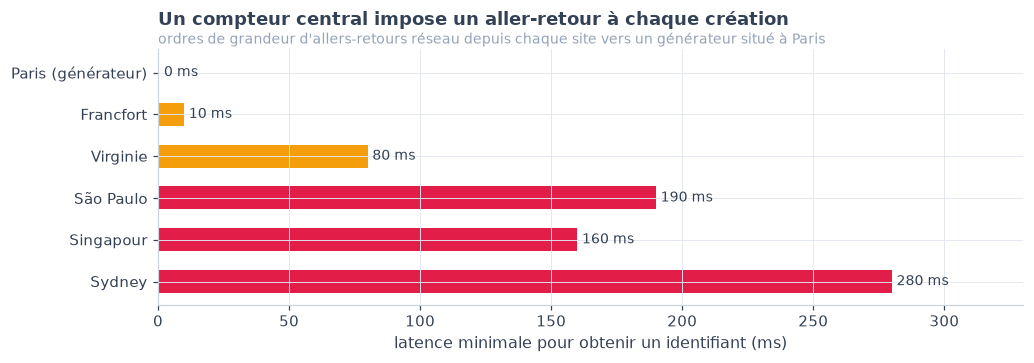

In [3]:
regions = pd.DataFrame({"site": ["Paris (générateur)", "Francfort", "Virginie", "São Paulo", "Singapour", "Sydney"],
                        "aller_retour_ms": [0.5, 10, 80, 190, 160, 280]})
fig, ax = plt.subplots(figsize=(9.5, 3.4))
cols = [GREEN] + [AMBER if v < 100 else ROSE for v in regions.aller_retour_ms[1:]]
ax.barh(regions.site[::-1], regions.aller_retour_ms[::-1], color=cols[::-1], height=0.55)
annotate_bars(ax, "{:.0f} ms")
ax.set_xlabel("latence minimale pour obtenir un identifiant (ms)")
ax.set_xlim(0, 330)
ax.set_title("Un compteur central impose un aller-retour à chaque création")
subtitle(ax, "ordres de grandeur d'allers-retours réseau depuis chaque site vers un générateur situé à Paris")
plt.tight_layout(); plt.show()

Un client de Sydney paie plus d'un quart de seconde **avant même** d'écrire son
enregistrement. D'où l'envie de distribuer la génération d'identifiants.

> **À retenir.** Un compteur sur un nœud donne des identifiants compacts, uniques et
> ordonnés comme le temps réel (il est linéarisable), mais il n'est ni tolérant aux
> pannes, ni proche de tous les clients, ni extensible.

## 3. Les générateurs distribués perdent l'ordre (section *ID Generators and Logical Clocks*)

Trois façons classiques de générer des identifiants sur plusieurs nœuds sans coordination
à chaque demande :

- **par partition** (sharded) : le nœud $k$ sur $n$ distribue $k, k + n, k + 2n$... (pairs
  et impairs pour deux nœuds) ; plus généralement, quelques bits de l'identifiant
  contiennent le numéro du nœud ;
- **par blocs préalloués** : chaque nœud réserve auprès d'un générateur central un bloc
  (1 à 1 000, puis 1 001 à 2 000...) et le distribue localement ;
- **par horloge murale** : l'heure du nœud (synchronisée par NTP) dans les bits de poids
  fort, complétée par le numéro du nœud et une séquence pour garantir l'unicité.

Tous trois donnent des identifiants **uniques**. Mesurons leur **ordre** : 3 nœuds
traitent 20 000 demandes réparties au hasard ; le nœud 2 reçoit deux fois plus de
demandes que les autres ; les horloges sont décalées de -3, 0 et +5 ms. Pour un écart
$g$, on estime la probabilité qu'une demande commencée $g$ **après** une autre reçoive un
identifiant **plus petit** (`cs.assign_ids`, `cs.inversion_curve`).

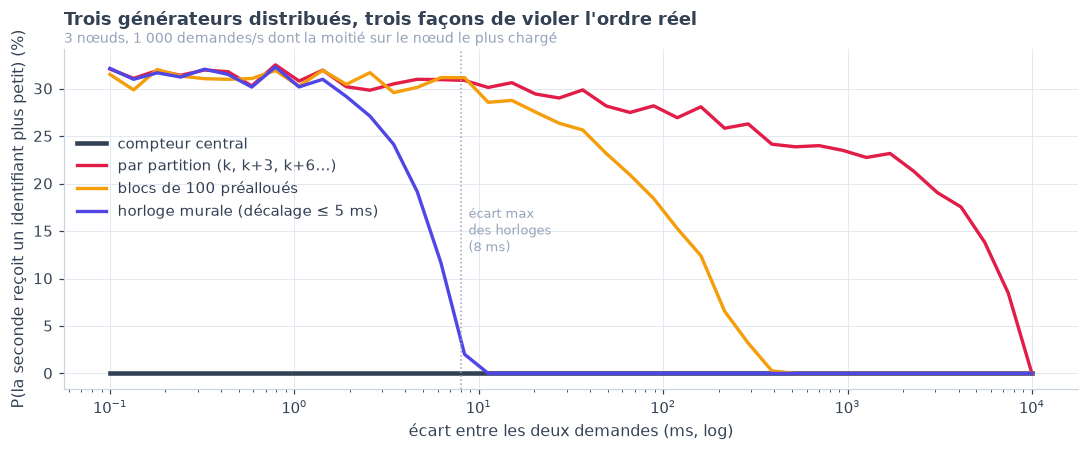

,écart 1.91 ms,écart 36.7 ms,écart 702 ms,écart 1e+04 ms
compteur central,0.000,0.000,0.00,0.0
"par partition (k, k+3, k+6...)",0.302,0.299,0.24,0.0
blocs de 100 préalloués,0.305,0.257,0.00,0.0
horloge murale (décalage ≤ 5 ms),0.292,0.000,0.00,0.0


In [4]:
N = 20_000
times = np.sort(rng.uniform(0, 20.0, N))                      # 20 s, 1 000 demandes/s
nodes_ = rng.choice(3, N, p=[0.25, 0.25, 0.5])
offs = [-0.003, 0.0, 0.005]
gaps = np.geomspace(1e-4, 10, 40)
schemes = {"central": ("compteur central", SLATE), "sharded": ("par partition (k, k+3, k+6...)", ROSE),
           "blocks": ("blocs de 100 préalloués", AMBER), "wallclock": ("horloge murale (décalage ≤ 5 ms)", INDIGO)}
fig, ax = plt.subplots(figsize=(10, 4.2))
curves = {}
for sch, (lab, c) in schemes.items():
    ids = cs.assign_ids(sch, times, nodes_, 3, block=100, offsets=offs)
    curves[sch] = cs.inversion_curve(times, ids, gaps, n_pairs=6000, seed=1)
    ax.plot(gaps * 1000, curves[sch] * 100, color=c, label=lab, lw=2.2 if sch != "central" else 3)
ax.set_xscale("log")
ax.axvline(8, color=GRAY, ls=":", lw=1)
ax.text(8.8, 15, "écart max\ndes horloges\n(8 ms)", fontsize=8.5, color=GRAY, va="center")
ax.set_xlabel("écart entre les deux demandes (ms, log)")
ax.set_ylabel("P(la seconde reçoit un identifiant plus petit) (%)")
ax.set_title("Trois générateurs distribués, trois façons de violer l'ordre réel")
subtitle(ax, "3 nœuds, 1 000 demandes/s dont la moitié sur le nœud le plus chargé")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.62))
plt.tight_layout(); plt.show()
pd.DataFrame({schemes[k][0]: v[[10, 20, 30, 39]] for k, v in curves.items()},
             index=[f"écart {g * 1000:.3g} ms" for g in gaps[[10, 20, 30, 39]]]).T

- **Par partition** : les compteurs avancent à des vitesses différentes (le nœud chargé
  distribue deux fois plus vite), si bien que l'écart entre compteurs **grandit avec le
  temps** : au bout de $t$ secondes, une demande servie par un nœud peu chargé peut
  recevoir un identifiant plus petit qu'une demande antérieure de près de $t$ secondes.
  La courbe ne retombe à droite que parce que la simulation ne dure que 20 s ; sur un an,
  l'ordre ne voudrait plus rien dire.
- **Par blocs** : tant que les deux demandes tombent dans des blocs différents encore en
  cours, l'ordre est arbitraire ; il ne se rétablit qu'au-delà de la durée de vie d'un bloc.
- **Par horloge murale** : l'ordre n'est faux que pour des demandes plus proches que le
  décalage des horloges (quelques ms) ; au-delà, il est correct. C'est le meilleur des
  trois... **si** les horloges restent synchronisées : un saut d'horloge (NTP qui recule)
  désordonne même les identifiants d'un seul nœud (chapitre 9).

Aucun n'est **cohérent avec la causalité** : si un nœud lent attribue l'identifiant d'une
réponse, celle-ci peut paraître antérieure à la question.

**UUID et identifiants horodatés.** Deux familles très répandues complètent ce tableau :

- les **UUID aléatoires** (version 4) : 122 bits aléatoires sur 128, générés sans aucune
  communication ; la collision est astronomiquement improbable, mais l'ordre est
  **aléatoire** et ils occupent deux fois plus de place qu'un entier de 64 bits ;
- les identifiants **horodatés rendus uniques** : l'heure dans les bits de poids fort,
  puis un numéro de nœud et une séquence, ou des bits aléatoires. C'est le principe des
  UUID version 7, de Snowflake (X), des ULID, des ObjectId de MongoDB ou du générateur
  Flake de Hazelcast, implémentables dans l'application ou dans la base.

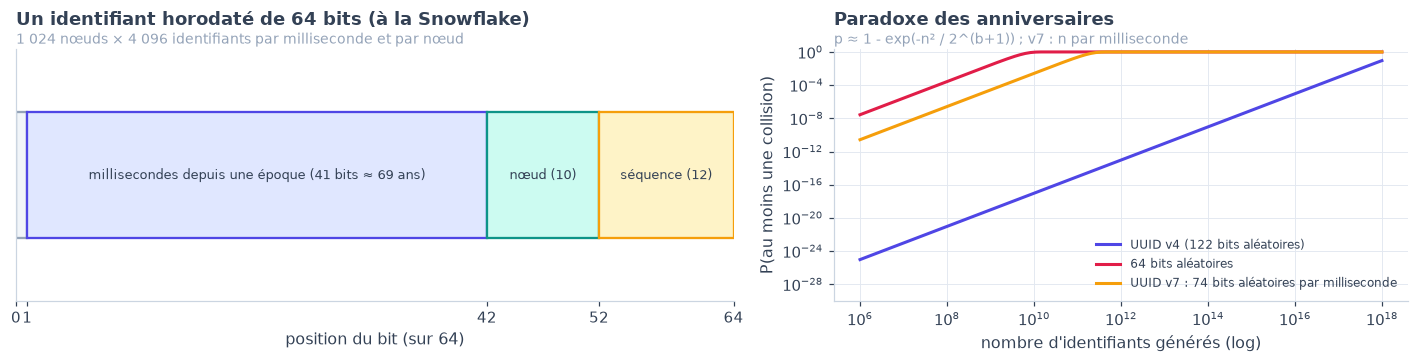

In [5]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[1.25, 1]))
champs = [("signe", 1, GRAY), ("millisecondes depuis une époque (41 bits ≈ 69 ans)", 41, INDIGO),
          ("nœud (10)", 10, TEAL), ("séquence (12)", 12, AMBER)]
x0 = 0
for nom, w, c in champs:
    ax.barh(0, w, left=x0, color=LIGHT[c], edgecolor=c, lw=1.5, height=0.6)
    ax.text(x0 + w / 2, 0, nom if w > 5 else "", ha="center", va="center", fontsize=8.5, color=SLATE)
    x0 += w
ax.set_xlim(0, 64); ax.set_ylim(-0.6, 0.6); ax.set_yticks([]); ax.grid(False)
ax.set_xticks([0, 1, 42, 52, 64])
ax.set_xlabel("position du bit (sur 64)")
ax.set_title("Un identifiant horodaté de 64 bits (à la Snowflake)")
subtitle(ax, "1 024 nœuds × 4 096 identifiants par milliseconde et par nœud")
n_ids = np.geomspace(1e6, 1e18, 200)
for bits, c, lab in [(122, INDIGO, "UUID v4 (122 bits aléatoires)"), (64, ROSE, "64 bits aléatoires"),
                     (74, AMBER, "UUID v7 : 74 bits aléatoires par milliseconde")]:
    p = -np.expm1(-n_ids ** 2 / 2 ** (bits + 1))
    ax2.plot(n_ids, np.maximum(p, 1e-30), color=c, label=lab)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_ylim(1e-30, 2)
ax2.set_xlabel("nombre d'identifiants générés (log)")
ax2.set_ylabel("P(au moins une collision)")
ax2.set_title("Paradoxe des anniversaires")
subtitle(ax2, "p ≈ 1 - exp(-n² / 2^(b+1)) ; v7 : n par milliseconde")
ax2.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

Avec 122 bits aléatoires, il faut générer de l'ordre de $10^{17}$ identifiants pour
atteindre une chance sur un milliard de collision ; avec 64 bits, la même probabilité est
atteinte dès quelques centaines de milliers. Les identifiants horodatés sont triables
(pratique pour les index B-tree, chapitre 4), mais leur ordre n'est que celui
des horloges : approximatif, comme on vient de le mesurer. Pour réduire ces incohérences,
on peut s'appuyer sur une synchronisation d'horloges de haute précision (horloges
atomiques, GPS). Mais peut-on obtenir des identifiants correctement ordonnés **sans**
matériel spécial ?

> **À retenir.** Partition, blocs, horloge murale : trois générateurs uniques et sans
> coordination, mais dont l'ordre ne respecte ni le temps réel ni la causalité. Le moins
> mauvais (l'horloge) ne se trompe qu'à l'échelle du décalage des horloges.

## 4. Les horloges de Lamport : un ordre total compatible avec la causalité (section *Lamport timestamps*)

Une **horloge logique** ne mesure pas le temps : c'est un algorithme qui **compte des
événements**. On attend d'elle des horodatages compacts et uniques, comparables deux à
deux (ordre total), et **cohérents avec la causalité** : si $a \to b$, alors
$T(a) < T(b)$. Le compteur sur un nœud y parvient ; les générateurs distribués précédents,
non.

Leslie Lamport a proposé en 1978 (dans l'un des articles les plus cités du domaine) une
méthode simple. Chaque nœud a un identifiant unique et un compteur ; l'horodatage est le
couple **(compteur, identifiant du nœud)**.

1. Pour chaque nouvel événement (ou envoi), le nœud **incrémente** son compteur et utilise
   la nouvelle valeur.
2. Quand il voit un horodatage (dans un message reçu) dont le compteur est plus grand que
   le sien, il **avance** son compteur jusqu'à cette valeur.
3. On compare d'abord les compteurs, puis, à égalité, les identifiants des nœuds.

Pourquoi est-ce cohérent avec la causalité ? Sur un nœud, le compteur croît
strictement ; à la réception, le compteur dépasse celui de l'émetteur, puis
l'événement suivant l'incrémente. Par récurrence sur un chemin causal, les compteurs
croissent strictement. Illustration dans une messagerie : Chloé pose une question,
Inès et Bastien la reçoivent, Inès répond ; Bastien, qui n'a pas encore vu la réponse
d'Inès, poste un message de son côté, puis répond à Inès.

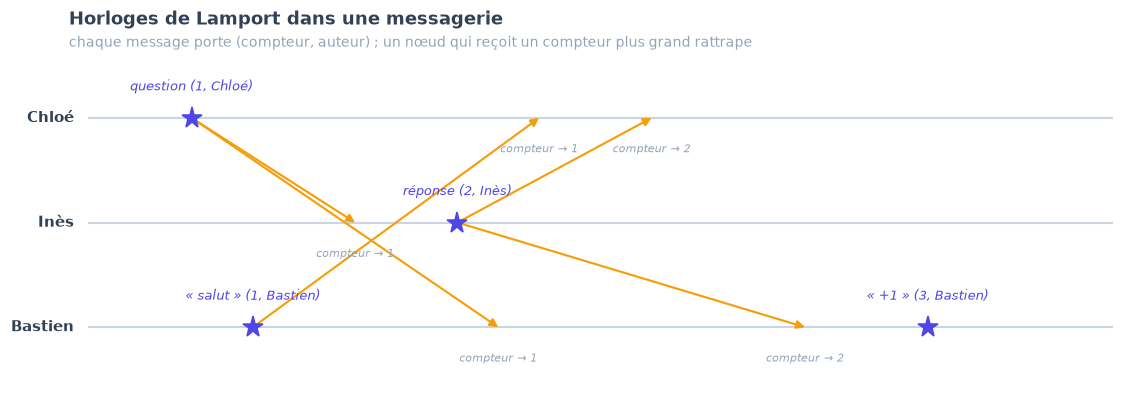

ordre total des messages : (1, Bastien) < (1, Chloé) < (2, Inès) < (3, Bastien)


In [6]:
users = ["Chloé", "Inès", "Bastien"]
L = {u: cs.LamportClock(u) for u in users}
st = SpaceTime(users, t_max=10, width=10.5, title="Horloges de Lamport dans une messagerie",
               subtitle="chaque message porte (compteur, auteur) ; un nœud qui reçoit un compteur plus grand rattrape", show_axis=False)
def poste(u, t, texte):
    ts = L[u].tick()
    st.event(u, t, "", kind="star", color=INDIGO)
    st.note(t, u, f"{texte} ({ts[0]}, {ts[1]})", dy=0.3, color=INDIGO)
    return ts
def recoit(u, t, ts, src, t_env):
    L[u].observe(ts)
    st.msg(src, t_env, u, t, "", color=AMBER)
    st.note(t, u, f"compteur → {L[u].counter}", dy=-0.3, color=GRAY, fontsize=7.5)
q = poste("Chloé", 1.0, "question")
b0 = poste("Bastien", 1.6, "« salut »")
recoit("Inès", 2.6, q, "Chloé", 1.0)
r = poste("Inès", 3.6, "réponse")
recoit("Bastien", 4.0, q, "Chloé", 1.0)
recoit("Chloé", 4.4, b0, "Bastien", 1.6)
recoit("Chloé", 5.5, r, "Inès", 3.6)
recoit("Bastien", 7.0, r, "Inès", 3.6)
b1 = poste("Bastien", 8.2, "« +1 »")
st.show()
ordre = sorted([q, b0, r, b1])
print("ordre total des messages :", " < ".join(f"({c}, {u})" for c, u in ordre))

Le « salut » de Bastien et la question de Chloé sont concurrents et ont le même compteur
(1) : l'identifiant du nœud les départage (arbitrairement mais de la même façon pour
tous). La réponse d'Inès (2) vient après la question, et le « +1 » de Bastien (3) après
la réponse : l'ordre respecte la causalité, sans aucune horloge physique.

**Vérification à grande échelle.** `cs.run_chat` simule quatre utilisateurs qui postent
et répondent pendant 20 minutes ; leurs horloges physiques sont décalées. On compte,
parmi les paires de messages **causalement liées** (vérité donnée par les horloges
vectorielles), celles que chaque horodatage range à l'envers.

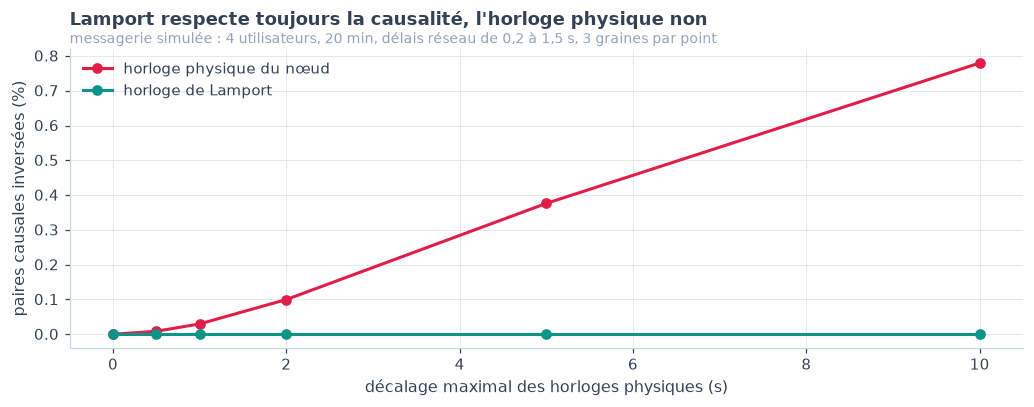

horodatage,horloge de Lamport,horloge physique du nœud
décalage,,
0.0,0.0,0.000e+00
0.5,0.0,8.613e-05
1.0,0.0,2.976e-04
2.0,0.0,9.981e-04
5.0,0.0,3.762e-03
10.0,0.0,7.796e-03


In [7]:
rows = []
for skew in [0.0, 0.5, 1, 2, 5, 10]:
    offs_ = [0.0, skew, -skew / 2, skew / 3]
    for seed in range(3):
        ev = cs.run_chat(n_users=4, duration=1200, rate=0.02, reply_prob=0.25, think=4.0, offsets=offs_,
                         latency=(0.2, 1.5), seed=seed)
        for key, lab in [("t_phys", "horloge physique du nœud"), ("lamport", "horloge de Lamport")]:
            r_ = cs.causal_order_errors(ev, key)
            rows.append(dict(décalage=skew, horodatage=lab, taux=r_["taux_inversion"], conc=r_["part_concurrentes"]))
R = pd.DataFrame(rows).groupby(["décalage", "horodatage"]).mean().reset_index()
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for lab, c in [("horloge physique du nœud", ROSE), ("horloge de Lamport", TEAL)]:
    g = R[R.horodatage == lab]
    ax.plot(g["décalage"], g["taux"] * 100, "o-", color=c, label=lab)
ax.set_xlabel("décalage maximal des horloges physiques (s)")
ax.set_ylabel("paires causales inversées (%)")
ax.set_title("Lamport respecte toujours la causalité, l'horloge physique non")
subtitle(ax, "messagerie simulée : 4 utilisateurs, 20 min, délais réseau de 0,2 à 1,5 s, 3 graines par point")
ax.legend()
plt.tight_layout(); plt.show()
R.pivot(index="décalage", columns="horodatage", values="taux")

Dès que les horloges divergent d'une fraction de seconde, une partie des réponses
paraît antérieure à la question si l'on trie par horloge physique ; l'horloge de Lamport
ne commet **aucune** inversion, quel que soit le décalage.

**Ce que Lamport ne garantit pas.** Un horodatage de Lamport est seulement plus grand que
tout ce que le nœud **a vu**. Il ne dit rien des événements qu'il n'a pas vus : ce n'est
**pas** une garantie de fraîcheur, donc pas de linéarisabilité. Deux nœuds qui ne
communiquent pas peuvent avoir des compteurs très différents pour des événements
simultanés.

> **À retenir.** Horloge de Lamport : (compteur, nœud), incrément à chaque événement,
> rattrapage à chaque réception. On obtient un ordre total compact et cohérent avec la
> causalité, mais sans lien avec le temps réel.

## 5. Les horloges vectorielles : reconnaître la concurrence (section *Lamport/hybrid logical clocks versus vector clocks*)

Un ordre total range **arbitrairement** les événements concurrents. En regardant deux
horodatages de Lamport, on ne peut donc pas savoir si les événements étaient concurrents
ou causalement liés (sauf compteurs égaux, qui prouvent la concurrence). Pour le savoir,
il faut une **horloge vectorielle** : un compteur **par nœud**, transmis avec chaque
message (le principe des vecteurs de versions du chapitre 6). Si $a$ a un
compteur plus grand pour un nœud et $b$ pour un autre, ils sont concurrents.

Les horloges de Lamport (et hybrides, section 7) servent volontiers à générer les
identifiants de transactions de l'isolation par instantané : une transaction voit les
écritures des transactions d'identifiant inférieur, et l'instantané est alors cohérent
avec la causalité. Mais pour **détecter** des écritures concurrentes (et les fusionner),
il faut des vecteurs.

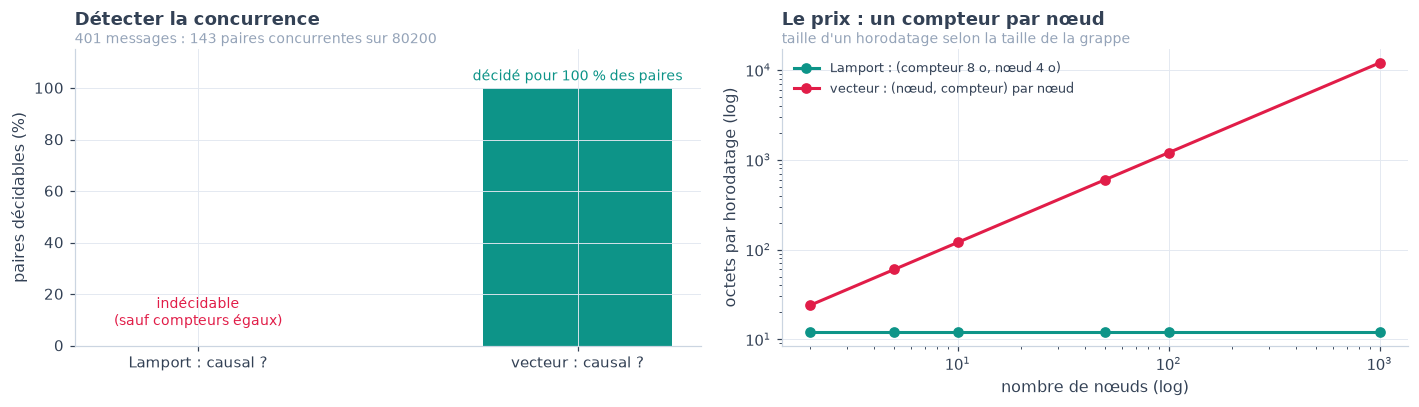

In [8]:
ev = cs.run_chat(n_users=4, duration=1200, rate=0.02, reply_prob=0.25, think=4.0, latency=(0.2, 1.5), seed=0)
pairs = {"causales, rangées dans le bon ordre": 0, "concurrentes, rangées arbitrairement": 0}
for i in range(len(ev)):
    for j in range(i + 1, len(ev)):
        rel = cs.vc_compare(ev[i]["vc"], ev[j]["vc"])
        pairs["concurrentes, rangées arbitrairement" if rel == "||" else "causales, rangées dans le bon ordre"] += 1
nn = np.array([2, 5, 10, 50, 100, 1000])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax.bar(["Lamport : causal ?", "vecteur : causal ?"], [0, 100], color=[ROSE, TEAL], width=0.5)
ax.set_ylim(0, 115)
ax.text(0, 8, "indécidable\n(sauf compteurs égaux)", ha="center", fontsize=9, color=ROSE)
ax.text(1, 103, "décidé pour 100 % des paires", ha="center", fontsize=9, color=TEAL)
ax.set_ylabel("paires décidables (%)")
ax.set_title("Détecter la concurrence")
subtitle(ax, f"{len(ev)} messages : {pairs['concurrentes, rangées arbitrairement']} paires concurrentes sur {sum(pairs.values())}")
ax2.plot(nn, np.full(len(nn), 12), "o-", color=TEAL, label="Lamport : (compteur 8 o, nœud 4 o)")
ax2.plot(nn, 12 * nn, "o-", color=ROSE, label="vecteur : (nœud, compteur) par nœud")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("nombre de nœuds (log)"); ax2.set_ylabel("octets par horodatage (log)")
ax2.set_title("Le prix : un compteur par nœud")
subtitle(ax2, "taille d'un horodatage selon la taille de la grappe")
ax2.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

> **À retenir.** Lamport ordonne tout, y compris le concurrent, arbitrairement ; le vecteur
> dit exactement ce qui est concurrent, au prix d'un compteur par nœud dans chaque
> horodatage.

## 6. Des horodatages ne suffisent pas à imposer une contrainte (section *Enforcing constraints using logical clocks*)

Au cours 1, un CAS linéarisable permettait d'imposer l'unicité d'un nom d'utilisateur.
Un ordre total de Lamport suffirait-il ? Idée : si deux personnes demandent le même nom,
la demande de plus petit horodatage gagne. **Après coup**, en rassemblant toutes les
demandes, c'est correct. Mais un nœud doit répondre **tout de suite** : la demande est-elle
acceptée ? Pour en être sûr, il doit savoir qu'**aucun autre nœud** n'a émis (ou
n'émettra) une demande concurrente de plus petit horodatage. Il doit donc **interroger
tous les nœuds**. Si un seul est en panne ou injoignable, tout s'arrête.

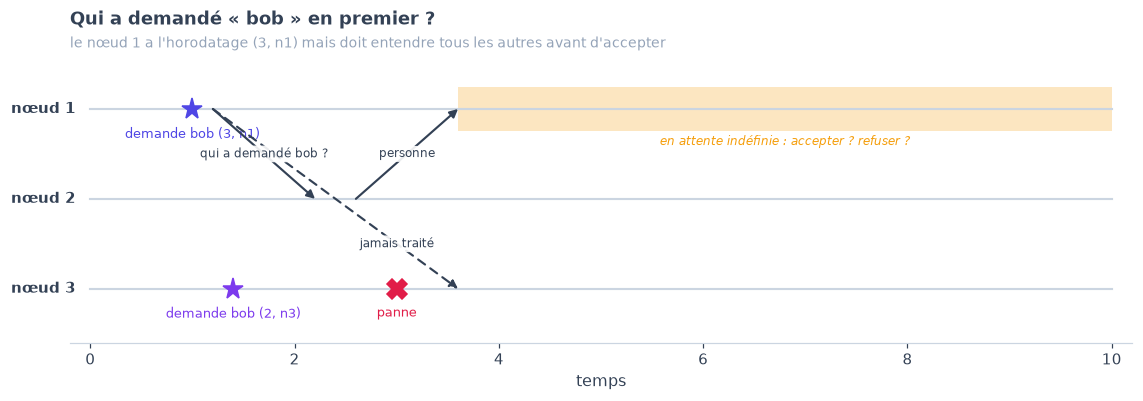

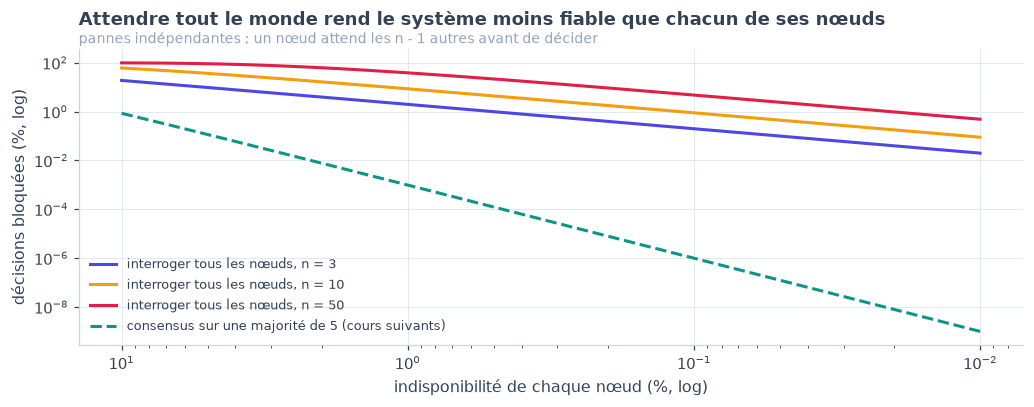

In [9]:
st = SpaceTime(["nœud 1", "nœud 2", "nœud 3"], t_max=10, width=10.5,
               title="Qui a demandé « bob » en premier ?",
               subtitle="le nœud 1 a l'horodatage (3, n1) mais doit entendre tous les autres avant d'accepter")
st.event("nœud 1", 1.0, "demande bob (3, n1)", kind="star", color=INDIGO)
st.event("nœud 3", 1.4, "demande bob (2, n3)", kind="star", color=VIOLET)
st.msg("nœud 1", 1.2, "nœud 2", 2.2, "qui a demandé bob ?", color=SLATE)
st.msg("nœud 2", 2.6, "nœud 1", 3.6, "personne", color=SLATE)
st.msg("nœud 1", 1.2, "nœud 3", 3.6, "jamais traité", color=SLATE, style="dashed", label_pos=0.75)
st.event("nœud 3", 3.0, "panne", kind="crash")
st.span("nœud 1", 3.6, 10, "en attente indéfinie : accepter ? refuser ?", color=AMBER)
st.show()

p = np.linspace(0.9, 0.9999, 300)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for n_, c in [(3, INDIGO), (10, AMBER), (50, ROSE)]:
    ax.plot((1 - p) * 100, (1 - p ** (n_ - 1)) * 100, color=c, label=f"interroger tous les nœuds, n = {n_}")
ax.plot((1 - p) * 100, [(1 - cs.majority_availability(5, x)) * 100 for x in p], color=TEAL, ls="--",
        label="consensus sur une majorité de 5 (cours suivants)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xlabel("indisponibilité de chaque nœud (%, log)")
ax.set_ylabel("décisions bloquées (%, log)")
ax.set_title("Attendre tout le monde rend le système moins fiable que chacun de ses nœuds")
subtitle(ax, "pannes indépendantes ; un nœud attend les n - 1 autres avant de décider")
ax.legend(fontsize=8.5, loc="lower left")
plt.tight_layout(); plt.show()

Attendre tous les nœuds multiplie les risques : avec 50 nœuds disponibles à 99,9 %, près
de 5 % des décisions sont bloquées. Ce n'est pas le système tolérant aux pannes que l'on
cherche. Même un générateur d'identifiants **linéarisable** n'y suffirait pas seul : il garantit que toute demande **future** aura un plus grand identifiant, mais pas que le nœud **sait** qu'il a gagné face aux demandes concurrentes en vol. Pour verrous, baux et
unicité tolérants aux pannes, il faut plus fort que des horloges : il faut que tous les
nœuds **s'accordent** sur l'ordre des demandes, et que cet accord survive à la panne
d'une minorité. C'est le **consensus**.

> **À retenir.** Un ordre total d'horodatages ne permet de désigner le gagnant qu'**après
> coup**, une fois toutes les demandes connues. Pour décider immédiatement et malgré les
> pannes, il faut un consensus.

## 7. Les horloges logiques hybrides (section *Hybrid logical clocks*)

Les horloges de Lamport ont deux limites pratiques : sans lien avec le temps physique, on
ne peut pas s'en servir pour retrouver « les messages du 3 mars » (il faut stocker l'heure
à part) ; et deux nœuds qui communiquent peu ont des compteurs très différents pour des
événements simultanés. Une **horloge logique hybride** (HLC, Kulkarni et al., 2014)
combine les deux mondes : elle compte en (micro)secondes comme une horloge physique, et
comme Lamport, un nœud qui voit un horodatage plus grand que le sien avance jusqu'à lui.
Un petit compteur départage les événements de la même tranche de temps et garantit la
monotonie même si l'horloge physique recule (ajustement NTP). L'horodatage reste donc très
proche de l'heure physique (il ne la dépasse que de l'avance de l'horloge la plus en
avance qu'on a vue), tout en respectant la relation « s'est produit avant ». Aucun
matériel spécial : des horloges grossièrement synchronisées suffisent. CockroachDB
l'utilise, par exemple.

Branchons `HybridLogicalClock` (module `ddia.consistency_clocks`) sur la messagerie, avec
des horloges décalées de 0, +2, -1 et +0,7 s.

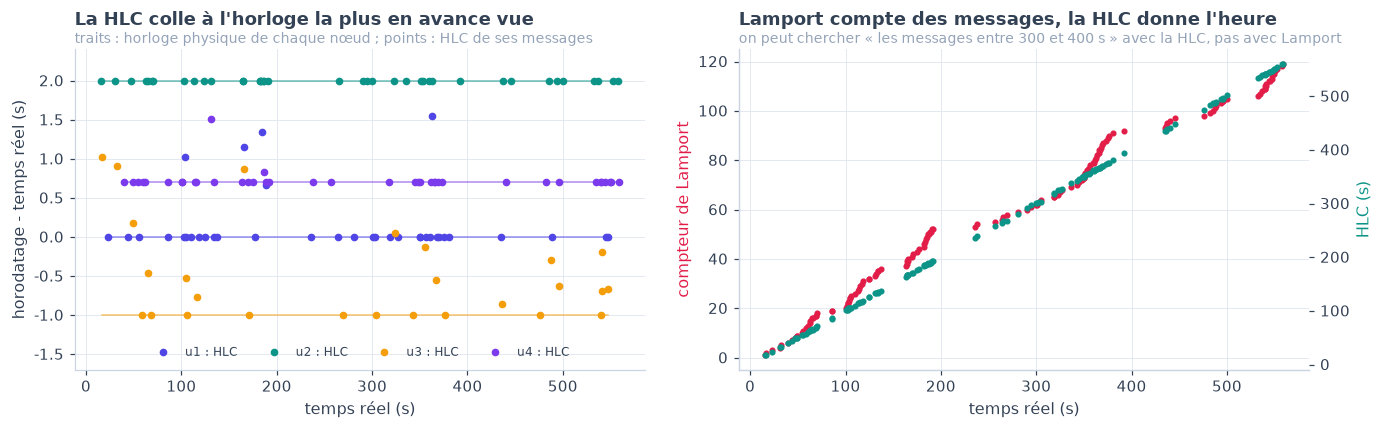

paires causales inversées : HLC 0 sur 9705 ; horloge physique 27


In [10]:
from ddia.consistency_clocks import HybridLogicalClock, hlc_factory

ev = cs.run_chat(n_users=4, duration=600, rate=0.02, reply_prob=0.25, think=4.0, offsets=[0, 2.0, -1.0, 0.7],
                 latency=(0.2, 1.5), seed=4, extra_clocks={"hlc": hlc_factory(1e-3)})
E = pd.DataFrame([dict(t=e["t_real"], user=e["user"], phys=e["t_phys"], lamport=e["lamport"][0],
                       hlc=e["hlc"][0] * 1e-3 + e["hlc"][1] * 1e-6) for e in ev])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for u, c in zip(sorted(E.user.unique()), [INDIGO, TEAL, AMBER, VIOLET]):
    g = E[E.user == u]
    ax.plot(g.t, g.hlc - g.t, "o", color=c, ms=4, label=f"{u} : HLC")
    ax.plot(g.t, g.phys - g.t, "-", color=c, lw=1, alpha=0.6)
ax.set_xlabel("temps réel (s)"); ax.set_ylabel("horodatage - temps réel (s)")
ax.set_title("La HLC colle à l'horloge la plus en avance vue")
subtitle(ax, "traits : horloge physique de chaque nœud ; points : HLC de ses messages")
ax.set_ylim(-1.7, 2.4)
ax.legend(fontsize=8, ncol=4, loc="lower center")
ax2.plot(E.t, E.lamport, ".", color=ROSE, label="Lamport (compteur)")
ax2b = ax2.twinx()
ax2b.plot(E.t, E.hlc, ".", color=TEAL, label="HLC (secondes)")
ax2b.grid(False)
ax2.set_xlabel("temps réel (s)"); ax2.set_ylabel("compteur de Lamport", color=ROSE)
ax2b.set_ylabel("HLC (s)", color=TEAL)
ax2.set_title("Lamport compte des messages, la HLC donne l'heure")
subtitle(ax2, "on peut chercher « les messages entre 300 et 400 s » avec la HLC, pas avec Lamport")
plt.tight_layout(); plt.show()
r_hlc = cs.causal_order_errors(ev, "hlc")
print(f"paires causales inversées : HLC {r_hlc['inversées']} sur {r_hlc['causales']} ; "
      f"horloge physique {cs.causal_order_errors(ev, 't_phys')['inversées']}")

Les nœuds en retard (-1 s, 0 s, +0,7 s) voient leur HLC rattraper l'horloge du nœud en
avance (+2 s) dès qu'ils reçoivent un de ses messages (ensuite, la partie physique de
leur HLC reste figée, seul le petit compteur avançant, jusqu'à ce que leur propre horloge
la rattrape : d'où les points intermédiaires) : l'écart avec le temps réel reste
borné par l'avance maximale, et l'ordre respecte la causalité (aucune inversion), alors
que l'horloge physique en commet.

> **À retenir.** Une HLC est un horodatage physique « corrigé à la Lamport » : proche de
> l'heure, monotone, cohérent avec la causalité, sans matériel spécial.

## 8. Les générateurs d'identifiants linéarisables (section *Linearizable ID Generators*)

Lamport et HLC garantissent qu'un nœud produit des horodatages supérieurs à tout ce qu'il
**a vu**. La linéarisabilité exige davantage : si la demande A s'est **terminée** avant que
B ne commence, B doit avoir le plus grand identifiant, **même si A et B n'ont jamais
communiqué**. La différence a des conséquences concrètes. Un utilisateur rend son compte
privé depuis son ordinateur, **puis** publie une photo gênante depuis son téléphone. Le
réglage et la photo sont dans deux bases (ou deux shards) horodatées par des horloges
logiques ; la base des photos, qui n'a rien lu de la base des comptes, a un compteur en
retard. Un visiteur lit le profil avec un instantané MVCC.

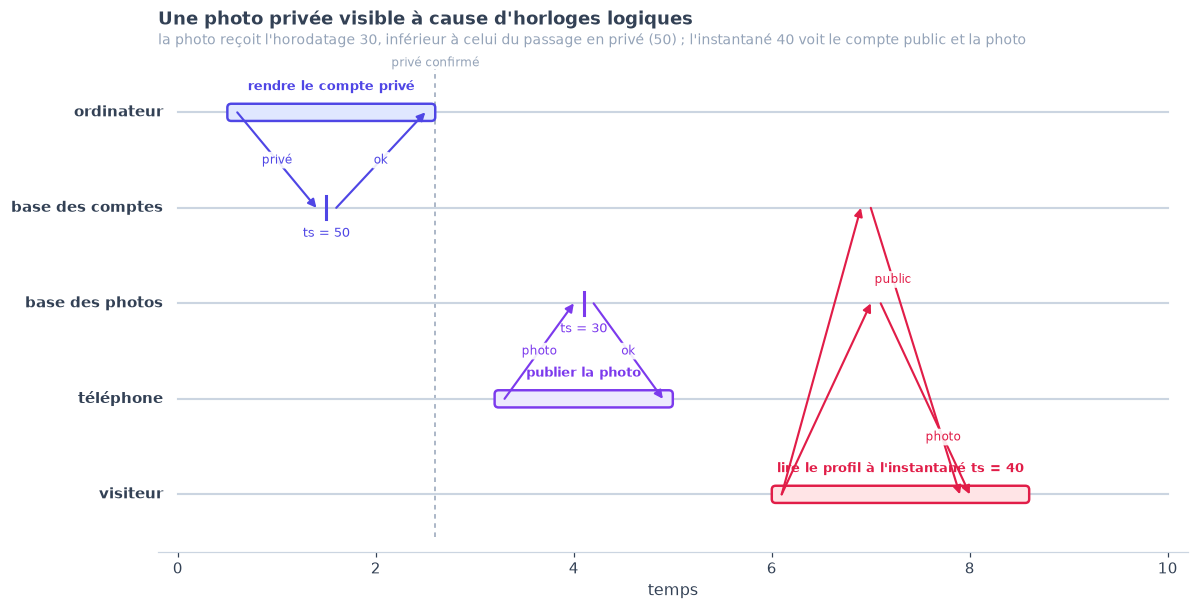

In [11]:
st = SpaceTime(["ordinateur", "base des comptes", "base des photos", "téléphone", "visiteur"], t_max=10, width=11,
               title="Une photo privée visible à cause d'horloges logiques",
               subtitle="la photo reçoit l'horodatage 30, inférieur à celui du passage en privé (50) ; l'instantané 40 voit le compte public et la photo")
st.op("ordinateur", 0.5, 2.6, "rendre le compte privé", color=INDIGO)
st.msg("ordinateur", 0.6, "base des comptes", 1.4, "privé", color=INDIGO)
st.event("base des comptes", 1.5, "ts = 50", kind="tick", color=INDIGO)
st.msg("base des comptes", 1.6, "ordinateur", 2.5, "ok", color=INDIGO)
st.op("téléphone", 3.2, 5.0, "publier la photo", color=VIOLET)
st.msg("téléphone", 3.3, "base des photos", 4.0, "photo", color=VIOLET)
st.event("base des photos", 4.1, "ts = 30", kind="tick", color=VIOLET)
st.msg("base des photos", 4.2, "téléphone", 4.9, "ok", color=VIOLET)
st.op("visiteur", 6.0, 8.6, "lire le profil à l'instantané ts = 40", color=ROSE)
st.msg("visiteur", 6.1, "base des comptes", 6.9, "", color=ROSE)
st.msg("base des comptes", 7.0, "visiteur", 7.9, "public", color=ROSE, label_pos=0.25)
st.msg("visiteur", 6.1, "base des photos", 7.0, "", color=ROSE)
st.msg("base des photos", 7.1, "visiteur", 8.0, "photo", color=ROSE, label_pos=0.7)
st.vline(2.6, "privé confirmé")
st.show()

On pourrait exiger que la base des photos lise d'abord l'état du compte (facile à
oublier) ou que l'application suive le dernier horodatage de l'utilisateur (difficile
entre deux appareils). Le plus simple : un **générateur linéarisable**, qui garantit que la
photo, publiée après la confirmation du passage en privé, reçoit un plus grand
identifiant.

**L'implémenter** (*Implementing a linearizable ID generator*). Le plus simple est...
un seul nœud, qui incrémente un compteur, le **persiste** (pour ne pas réémettre un
identifiant après un redémarrage) et le **réplique** (leader unique) pour tolérer les
pannes : c'est l'**oracle d'horodatage** de TiDB/TiKV, inspiré de Percolator chez Google.
Optimisation : persister et répliquer des **lots** d'identifiants plutôt que chaque
identifiant. Après une panne ou une bascule, l'oracle repart de la fin du lot persisté :
des identifiants sont **sautés**, mais jamais dupliqués ni désordonnés.

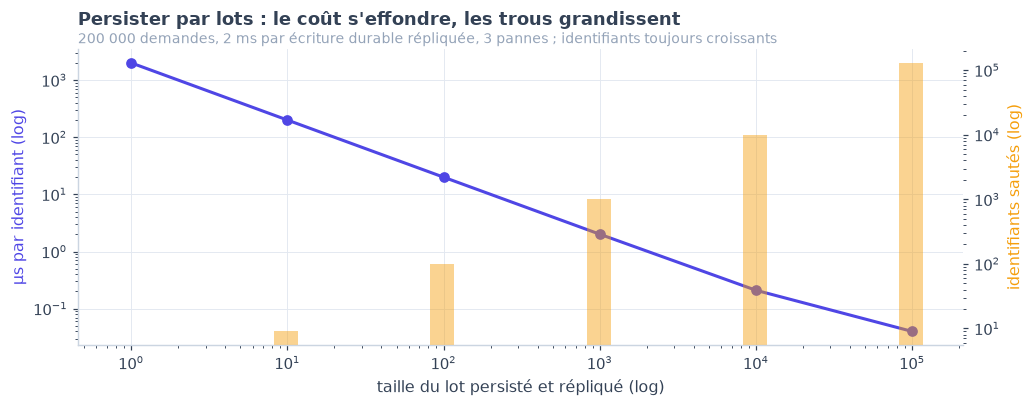

,lot,cout_moyen_ms,sautes,ordonnes
0,1,2.000e+00,0,True
1,10,2.000e-01,9,True
2,100,2.001e-02,99,True
3,1000,2.010e-03,999,True
4,10000,2.100e-04,9999,True
5,100000,4.000e-05,129999,True


In [12]:
from ddia.consistency_clocks import TimestampOracle

lots = [1, 10, 100, 1_000, 10_000, 100_000]
rows = []
g = np.random.default_rng(5)
for b in lots:
    o = TimestampOracle(batch=b, persist_cost=2.0)
    cout = 0.0
    for k in range(200_000):
        cout += o.get()[1]
        if k in (50_000, 120_000, 170_000):
            o.crash_and_recover()
    ids = np.array(o.issued)
    rows.append(dict(lot=b, cout_moyen_ms=cout / 200_000, sautes=o.skipped,
                     ordonnes=bool(np.all(np.diff(ids) > 0))))
T = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(T.lot, T.cout_moyen_ms * 1000, "o-", color=INDIGO, label="coût de persistance par identifiant (µs)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("taille du lot persisté et répliqué (log)")
ax.set_ylabel("µs par identifiant (log)", color=INDIGO)
ax2 = ax.twinx(); ax2.grid(False)
ax2.bar(T.lot, T.sautes, width=T.lot * 0.35, color=AMBER, alpha=0.45, label="identifiants sautés (3 pannes)")
ax2.set_yscale("log"); ax2.set_ylabel("identifiants sautés (log)", color=AMBER)
ax.set_title("Persister par lots : le coût s'effondre, les trous grandissent")
subtitle(ax, "200 000 demandes, 2 ms par écriture durable répliquée, 3 pannes ; identifiants toujours croissants")
plt.tight_layout(); plt.show()
T

Avec des lots de 10 000, la persistance coûte 0,2 µs par identifiant au lieu de 2 ms :
un seul nœud tient alors un débit énorme, ce qui compense le fait qu'on ne peut ni
**partitionner** l'oracle (plusieurs shards indépendants perdraient l'ordre
linéarisable) ni le **répartir entre régions** (toute demande va dans la région de
l'oracle). La contrepartie : au plus un lot d'identifiants sauté par panne, sans
importance pour des identifiants sur 64 bits.

**Sans nœud central : attendre l'incertitude.** Spanner procède autrement (chapitre
9) : son horloge renvoie un **intervalle** $[t - \varepsilon, t + \varepsilon]$
qui contient sûrement l'heure vraie, et il **attend** que l'intervalle soit écoulé avant de
répondre. Si une demande se termine avant qu'une autre ne commence, la seconde a donc un
plus grand horodatage, sans communication, même entre régions. Le prix : du matériel
(GPS, horloges atomiques) et un temps d'attente de l'ordre de $2\varepsilon$ par
validation, soit quelques millisecondes.

> **À retenir.** Un générateur linéarisable ordonne aussi les demandes qui ne se sont
> jamais vues. Un oracle sur un nœud répliqué, persistant par lots, le fait à très haut
> débit ; Spanner y parvient sans coordination en attendant l'incertitude de ses horloges.

## Synthèse

- La **causalité** est un ordre **partiel** ; la linéarisabilité impose un ordre **total**
  compatible avec le temps réel.
- Un **compteur sur un nœud** donne des identifiants ordonnés et linéarisables, mais c'est
  un point de défaillance unique, lointain pour certains clients.
- Les générateurs **distribués** (partition, blocs, horloge murale) sont uniques mais
  violent l'ordre réel et la causalité.
- Les **horloges de Lamport** donnent un ordre total compact cohérent avec la causalité ;
  les **horloges vectorielles** détectent en plus la concurrence, au prix d'un compteur
  par nœud. Les **horloges hybrides** restent proches de l'heure physique ; un **générateur linéarisable** (oracle par lots, ou attente de l'incertitude à la Spanner) ordonne même les demandes sans lien causal.
- Aucun horodatage ne permet de **décider immédiatement** d'une contrainte (unicité,
  verrou) en tolérant les pannes : il faut un **consensus**.

Liens : la relation « s'est produit avant » et les vecteurs de versions au chapitre
6, les horloges physiques et Spanner au chapitre 9, l'isolation
par instantané au chapitre 8. Le consensus est l'objet des cours 3 et 4.